# COU 07506: Digital Signal Processing
#Week 1 - Lab 0: Setting up the DSP Laboratory

* **Name:** EDSON STEVEN MARTIN
* **RegNo:** 240242494763
* **Class:** BENG24COE-2
* **Date:** 23/11/2026

Pre-lab question: list three devices you used today that contain DSP, and for each name one
signal it processes.

Answer

1. Smartphone, Processes audio signals during phone calls to reduce background noise and improve voice quality.

2. Laptop, Processes video signals from its webcam during video calls.

3. Bluetooth earphones, Process audio signals to produce sound and reduce unwanted background noise.

Task 1.1 - My first NOtebook

> Add blockquote



In [56]:

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

In [57]:

n = np.arange(-5, 11)

delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

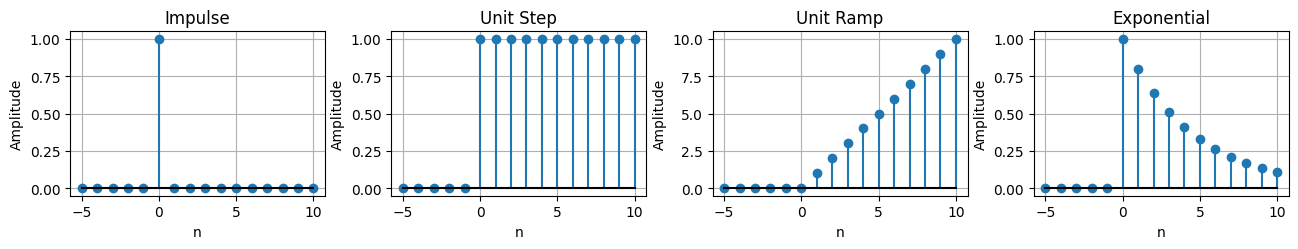

In [58]:

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["Impulse", "Unit Step", "Unit Ramp", "Exponential"]
):

    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

Task 1.2 - Change the parameters

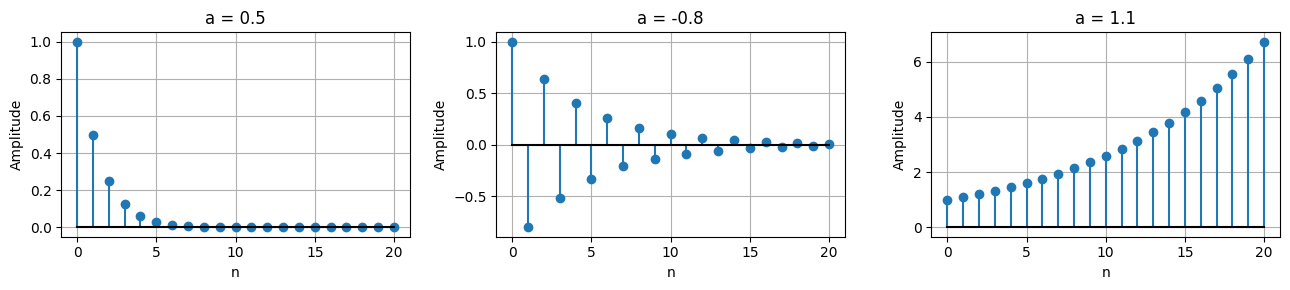

In [59]:

n = np.arange(0, 21)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):

    x = (a**n)

    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

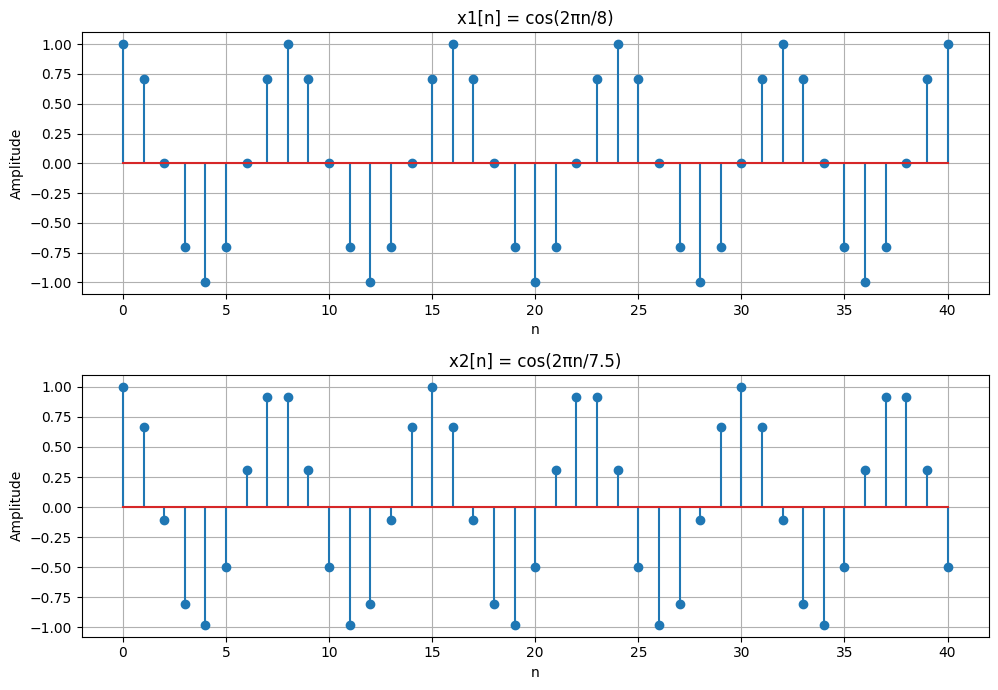

In [60]:
n = np.arange(0, 41)

# First cosine signal
x1 = np.cos(2 * np.pi * n / 8)

# Second cosine signal
x2 = np.cos(2 * np.pi * n / 7.5)

# Create two subplots
fig, axes = plt.subplots(2, 1, figsize=(10, 7))

axes[0].stem(n, x1)
axes[0].set_title("x1[n] = cos(2πn/8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)
axes[1].stem(n, x2)
axes[1].set_title("x2[n] = cos(2πn/7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)


plt.tight_layout()


plt.show()

Which one repeats exactly?

The first signal, x1[n]=cos⁡(2πn/8)
x1​[n]=cos(2πn/8), repeats exactly after every 8 samples.

Task 1.3 - Working with audio

In [61]:
!ffmpeg -y -i "/content/drive/MyDrive/my_voice" "/content/drive/MyDrive/my_voice_converted.wav"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

fs = 48000 Hz
duration = 6.36 s
samples = 305152


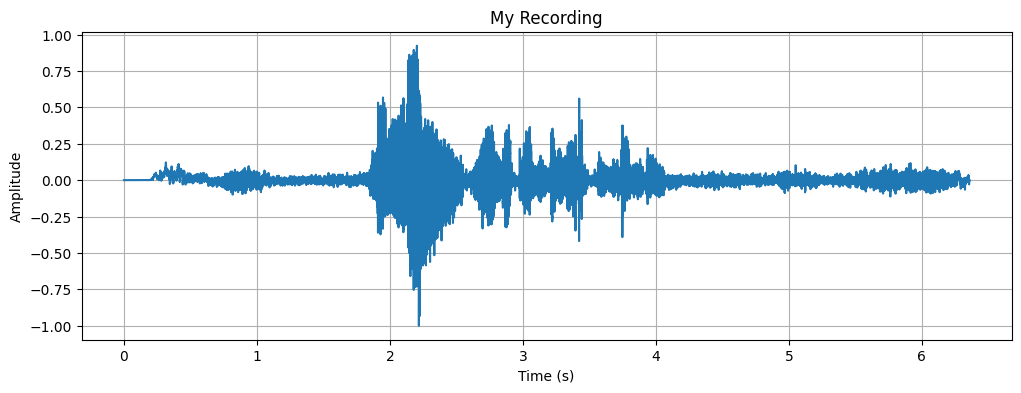

In [62]:


fname = "/content/drive/MyDrive/my_voice_converted.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        # Convert stereo audio to mono
        x = x.mean(axis=1)

    # Normalize audio to the range [-1, 1]
    x = x.astype(float)
    x = x / np.max(np.abs(x))

else:
    # Fallback test signal if recording is missing
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2*np.pi*440*t) * np.exp(-t)

# Generate time values
t = np.arange(len(x)) / fs

# Display recording information
print(f"fs = {fs} Hz")
print(f"duration = {len(x)/fs:.2f} s")
print(f"samples = {len(x)}")

# Plot the audio signal
plt.figure(figsize=(12, 4))
plt.plot(t, x)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("My Recording")
plt.grid(True)
plt.show()

# Listen to the recording
display(Audio(x, rate=fs))


Analysis questions

1.What is the sampling rate of your phone’s recording? How many numbers are needed to store
one minute of it in mono?

ans, The sampling rate is 44,100 Hz to store one minute of mono audio:
  
44,100 x 60 = 2,646,000

Therefore, 2,646,000 samples are needed to store one minute of audio.

2.Why is a stem plot more appropriate than a continuous line for 𝑥(𝑛)?

ans, A stem plot is more appropriate because a discrete-time signal consists of individual samples at specific integer values of .It clearly shows each sample separately, unlike a continuous line

3.For 𝑎 = 1.1 the exponential grows. Which property of a system would such a signal violate if it
were an impulse response (Unit 1 §1.7)?

ans, It would violate BIBO stability (Bounded Input Bounded Output stability) because the exponential signal grows continuously instead of decreasing. Its impulse response is not absolutely summable, making the system unstable